### Importa los datos
Dataset con diferentes fármacos, sus efectos y ratings de los clientes.

Importa el dataset *drugLibTrain_raw.tsv*

In [1]:
from pathlib import Path

import pandas as pd

DATA_PATH = Path('data/drugLibTrain_raw.tsv')

if not DATA_PATH.exists():
    raise FileNotFoundError(f'No se ha encontrado el archivo: {DATA_PATH.resolve()}')

df_drugs = pd.read_csv(DATA_PATH, sep='\t')

print(f'Dimensiones: {df_drugs.shape[0]} filas y {df_drugs.shape[1]} columnas')
display(df_drugs.head())

Dimensiones: 3107 filas y 9 columnas


,Unnamed: 0,urlDrugName,rating,effectiveness,sideEffects,condition,benefitsReview,sideEffectsReview,commentsReview
0,2202,enalapril,4,Highly Effective,Mild Side Effects,management of congestive heart failure,slowed the progression of left ventricular dys...,"cough, hypotension , proteinuria, impotence , ...","monitor blood pressure , weight and asses for ..."
1,3117,ortho-tri-cyclen,1,Highly Effective,Severe Side Effects,birth prevention,Although this type of birth control has more c...,"Heavy Cycle, Cramps, Hot Flashes, Fatigue, Lon...","I Hate This Birth Control, I Would Not Suggest..."
2,1146,ponstel,10,Highly Effective,No Side Effects,menstrual cramps,I was used to having cramps so badly that they...,Heavier bleeding and clotting than normal.,I took 2 pills at the onset of my menstrual cr...
3,3947,prilosec,3,Marginally Effective,Mild Side Effects,acid reflux,The acid reflux went away for a few months aft...,"Constipation, dry mouth and some mild dizzines...",I was given Prilosec prescription at a dose of...
4,1951,lyrica,2,Marginally Effective,Severe Side Effects,fibromyalgia,I think that the Lyrica was starting to help w...,I felt extremely drugged and dopey. Could not...,See above


### Descriptive Analysis

Quedate únicamente con las columnas que podamos manejar: Columnas numéricas y columnas categóricas con pocas categorías (menos de 10)

In [2]:

# Analizamos los tipos de datos y el número de valores únicos

for columna in df_drugs.columns:
    print(f"\nColumna: {columna}")
    print(f"Tipo: {df_drugs[columna].dtype}")
    print(f"Valores únicos: {df_drugs[columna].nunique()}")



Columna: Unnamed: 0
Tipo: int64
Valores únicos: 3107

Columna: urlDrugName
Tipo: object
Valores únicos: 502

Columna: rating
Tipo: int64
Valores únicos: 10

Columna: effectiveness
Tipo: object
Valores únicos: 5

Columna: sideEffects
Tipo: object
Valores únicos: 5

Columna: condition
Tipo: object
Valores únicos: 1426

Columna: benefitsReview
Tipo: object
Valores únicos: 3031

Columna: sideEffectsReview
Tipo: object
Valores únicos: 2813

Columna: commentsReview
Tipo: object
Valores únicos: 3046


#### Transforma las columnas categóricas

Transforma las columnas categoricas a numericas mediante dummies

In [3]:

# Seleccionamos las columnas numéricas y categóricas
df_drugs_clean = df_drugs[
    ['rating', 'effectiveness', 'sideEffects']
].copy()

# Comprobamos el resultado
display(df_drugs_clean.head())

# Analizamos la información del nuevo DataFrame
display(df_drugs_clean.describe(include='all'))


,rating,effectiveness,sideEffects
0,4,Highly Effective,Mild Side Effects
1,1,Highly Effective,Severe Side Effects
2,10,Highly Effective,No Side Effects
3,3,Marginally Effective,Mild Side Effects
4,2,Marginally Effective,Severe Side Effects


,rating,effectiveness,sideEffects
count,3107.000000,3107,3107
unique,NaN,5,5
top,NaN,Highly Effective,Mild Side Effects
freq,NaN,1330,1019
mean,7.006115,NaN,NaN
std,2.937582,NaN,NaN
min,1.000000,NaN,NaN
25%,5.000000,NaN,NaN
50%,8.000000,NaN,NaN
75%,9.000000,NaN,NaN


In [4]:

# Convertimos las variables categóricas en variables dummy

df_drugs_dummies = pd.get_dummies(
    df_drugs_clean,
    columns=['effectiveness', 'sideEffects'],
    dtype=int
)

# Comprobamos el resultado
display(df_drugs_dummies.head())

# Comprobamos las dimensiones
print("Dimensiones:", df_drugs_dummies.shape)


,rating,effectiveness_Considerably Effective,effectiveness_Highly Effective,effectiveness_Ineffective,effectiveness_Marginally Effective,effectiveness_Moderately Effective,sideEffects_Extremely Severe Side Effects,sideEffects_Mild Side Effects,sideEffects_Moderate Side Effects,sideEffects_No Side Effects,sideEffects_Severe Side Effects
0,4,0,1,0,0,0,0,1,0,0,0
1,1,0,1,0,0,0,0,0,0,0,1
2,10,0,1,0,0,0,0,0,0,1,0
3,3,0,0,0,1,0,0,1,0,0,0
4,2,0,0,0,1,0,0,0,0,0,1


Dimensiones: (3107, 11)


In [5]:

from sklearn.preprocessing import StandardScaler

# Creamos el escalador
scaler = StandardScaler()

# Aplicamos el escalado
X_scaled = scaler.fit_transform(df_drugs_dummies)

# Convertimos el resultado en DataFrame
df_drugs_scaled = pd.DataFrame(
    X_scaled,
    columns=df_drugs_dummies.columns
)

# Comprobamos el resultado
display(df_drugs_scaled.head())

print("Dimensiones:", df_drugs_scaled.shape)


,rating,effectiveness_Considerably Effective,effectiveness_Highly Effective,effectiveness_Ineffective,effectiveness_Marginally Effective,effectiveness_Moderately Effective,sideEffects_Extremely Severe Side Effects,sideEffects_Mild Side Effects,sideEffects_Moderate Side Effects,sideEffects_No Side Effects,sideEffects_Severe Side Effects
0,-1.023494,-0.652597,1.155894,-0.293877,-0.253063,-0.392633,-0.244308,1.431457,-0.496276,-0.653600,-0.367110
1,-2.044907,-0.652597,1.155894,-0.293877,-0.253063,-0.392633,-0.244308,-0.698589,-0.496276,-0.653600,2.723978
2,1.019330,-0.652597,1.155894,-0.293877,-0.253063,-0.392633,-0.244308,-0.698589,-0.496276,1.529987,-0.367110
3,-1.363965,-0.652597,-0.865131,-0.293877,3.951579,-0.392633,-0.244308,1.431457,-0.496276,-0.653600,-0.367110
4,-1.704436,-0.652597,-0.865131,-0.293877,3.951579,-0.392633,-0.244308,-0.698589,-0.496276,-0.653600,2.723978


Dimensiones: (3107, 11)


#### Evalua cual es la mejor K

Utiliza silhouette_score para evaluar cual es la mejor K.

#### Genera el K Means 

In [6]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Probamos diferentes números de clusters
silhouette_scores = []

for k in range(2, 11):

    # Creamos el modelo
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Entrenamos el modelo
    labels = kmeans.fit_predict(df_drugs_scaled)

    # Calculamos Silhouette Score
    score = silhouette_score(df_drugs_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k} | Silhouette Score = {score:.4f}")
    
# Identificamos la mejor K
best_k = range(2, 11)[
    silhouette_scores.index(max(silhouette_scores))
]

print(f"\nMejor número de clusters: {best_k}")


K = 2 | Silhouette Score = 0.3260
K = 3 | Silhouette Score = 0.2775
K = 4 | Silhouette Score = 0.3684
K = 5 | Silhouette Score = 0.4096
K = 6 | Silhouette Score = 0.4383
K = 7 | Silhouette Score = 0.4744
K = 8 | Silhouette Score = 0.5275
K = 9 | Silhouette Score = 0.5771
K = 10 | Silhouette Score = 0.6622

Mejor número de clusters: 10


In [7]:

# Creamos el modelo K-Means definitivo
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# Entrenamos el modelo y asignamos los clusters
df_drugs_clean['cluster'] = kmeans.fit_predict(df_drugs_scaled)

# Comprobamos los resultados
display(df_drugs_clean.head())

# Contamos los registros de cada cluster
print(df_drugs_clean['cluster'].value_counts().sort_index())


,rating,effectiveness,sideEffects,cluster
0,4,Highly Effective,Mild Side Effects,1
1,1,Highly Effective,Severe Side Effects,3
2,10,Highly Effective,No Side Effects,2
3,3,Marginally Effective,Mild Side Effects,4
4,2,Marginally Effective,Severe Side Effects,4


cluster
0    403
1    482
2    529
3    238
4    187
5    255
6    361
7    172
8    158
9    322
Name: count, dtype: int64


Comprueba los resultados y muestra en un pie plot la distribución de los distintos clusters.

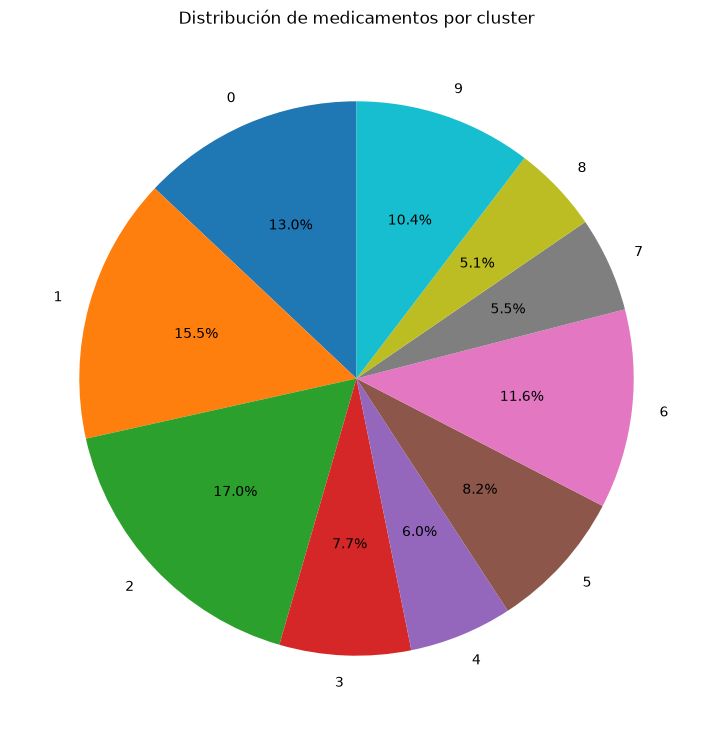

In [8]:

import matplotlib.pyplot as plt

# Calculamos el número de registros por cluster
cluster_counts = df_drugs_clean['cluster'].value_counts().sort_index()

# Creamos el gráfico circular
plt.figure(figsize=(9, 9))

plt.pie(
    cluster_counts,
    labels=cluster_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribución de medicamentos por cluster')
plt.show()
